# 04 — Do customers come back?

**Leadership question:** Do customers return and buy again?

## Definitions
- **Customer** = real person (`customer_unique_id`)
- **Orders counted:** all except `canceled` and `unavailable`; window Jan 2017 – Aug 2018
- **Returned** = bought again on a *later day* (several orders on the same day count as one visit)
- **Repeat purchase rate** = share of customers with purchases on 2+ different days
- **Cohort** = customers grouped by the month of their first purchase
- **Right-censoring:** recent cohorts had less time to return, so cohorts are compared at the same age, never on "ever returned"

In [1]:
from pathlib import Path
import duckdb

con = duckdb.connect(str(Path("../data/olist.duckdb")), read_only=True)

headline = con.sql("""
WITH valid AS (
    SELECT c.customer_unique_id,
           CAST(o.order_purchase_timestamp AS DATE) AS purchase_date
    FROM raw.orders o
    JOIN raw.customers c ON o.customer_id = c.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
),
visits AS (                       -- number each customer's purchase days: 1, 2, 3 ...
    SELECT customer_unique_id, purchase_date,
           DENSE_RANK() OVER (PARTITION BY customer_unique_id
                              ORDER BY purchase_date) AS visit_number
    FROM valid
),
per_customer AS (                 -- one row per customer
    SELECT customer_unique_id,
           MAX(visit_number)                                  AS purchase_days,
           MIN(purchase_date)                                 AS first_date,
           MIN(CASE WHEN visit_number = 2 THEN purchase_date END) AS second_date
    FROM visits
    GROUP BY customer_unique_id
)
SELECT COUNT(*)                                                  AS customers,
       SUM(CASE WHEN purchase_days >= 2 THEN 1 ELSE 0 END)       AS repeat_customers,
       AVG(CASE WHEN purchase_days >= 2 THEN 1 ELSE 0 END) * 100 AS repeat_rate_pct,
       MEDIAN(DATE_DIFF('day', first_date, second_date))         AS median_days_to_return
FROM per_customer
""").df()
headline.round(2)

,customers,repeat_customers,repeat_rate_pct,median_days_to_return
0,94707,2054.0,2.17,74.0


In [2]:
import pandas as pd

cohorts = con.sql("""
WITH valid AS (
    SELECT c.customer_unique_id,
           DATE_TRUNC('month', o.order_purchase_timestamp) AS purchase_month
    FROM raw.orders o
    JOIN raw.customers c ON o.customer_id = c.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
),
firsts AS (                         -- each customer's cohort = month of first purchase
    SELECT customer_unique_id, MIN(purchase_month) AS cohort_month
    FROM valid GROUP BY customer_unique_id
)
SELECT f.cohort_month,
       DATE_DIFF('month', f.cohort_month, v.purchase_month) AS month_number,
       COUNT(DISTINCT v.customer_unique_id)                 AS customers
FROM valid v
JOIN firsts f ON v.customer_unique_id = f.customer_unique_id
GROUP BY 1, 2
""").df()

# reshape into the matrix: rows = cohort, columns = months since first purchase
matrix = cohorts.pivot(index="cohort_month", columns="month_number", values="customers")
retention = matrix.div(matrix[0], axis=0) * 100

# right-censoring: fill true zeros with 0, but leave "not enough time yet" cells blank
max_age = (2018 - retention.index.year) * 12 + (8 - retention.index.month)
for cohort, age in zip(retention.index, max_age):
    observable = retention.columns <= age
    retention.loc[cohort, observable] = retention.loc[cohort, observable].fillna(0)

retention.index = retention.index.strftime("%Y-%m")
retention.iloc[:, :7].round(2)

month_number,0,1,2,3,4,5,6
cohort_month,,,,,,,
2017-01,100.0,0.40,0.27,0.13,0.40,0.13,0.40
2017-02,100.0,0.24,0.30,0.12,0.41,0.12,0.24
2017-03,100.0,0.51,0.35,0.39,0.35,0.16,0.16
2017-04,100.0,0.60,0.21,0.17,0.30,0.26,0.34
2017-05,100.0,0.48,0.48,0.40,0.31,0.34,0.42
2017-06,100.0,0.45,0.35,0.39,0.26,0.39,0.35
2017-07,100.0,0.52,0.34,0.24,0.29,0.21,0.31
2017-08,100.0,0.68,0.34,0.27,0.36,0.53,0.29
2017-09,100.0,0.69,0.54,0.29,0.44,0.22,0.22


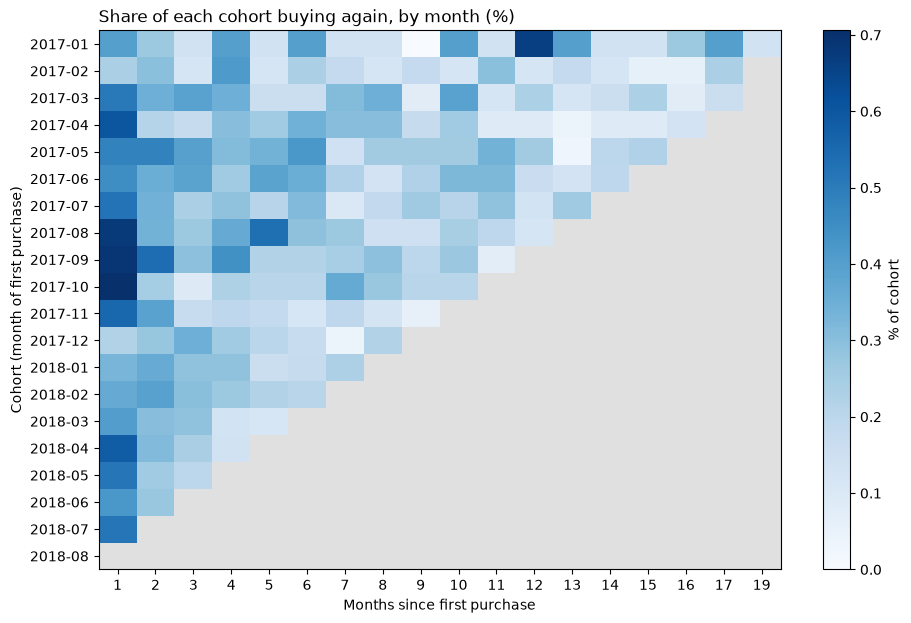

In [4]:
import numpy as np
import matplotlib.pyplot as plt

data = retention.drop(columns=0)          # drop month 0: always 100%, would wash out the colors

fig, ax = plt.subplots(figsize=(11, 7))
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#e0e0e0")                    # grey = not observable yet
im = ax.imshow(np.ma.masked_invalid(data.values), cmap=cmap, aspect="auto")
ax.set_xticks(range(data.shape[1]))
ax.set_xticklabels(data.columns)
ax.set_yticks(range(data.shape[0]))
ax.set_yticklabels(data.index)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (month of first purchase)")
ax.set_title("Share of each cohort buying again, by month (%)", loc="left")
fig.colorbar(im, ax=ax, label="% of cohort")
plt.show()

## Findings
- **Customers almost never come back.** Of 94,707 customers, only 2,054 (**2.17%**) bought again on a later day.
- **Those who return take time:** median **74 days** to the second purchase.
- **Retention is a tiny, flat trickle.** In any month after the first purchase, only ~0.1–0.7% of a cohort buys again, slightly higher in month 1.
- **Not improving over time.** 2018 cohorts return no more than 2017 cohorts.
- **Implication:** Olist's growth (question 1) relied almost entirely on acquiring *new* customers, which is a likely factor in the 2018 plateau. Retention is a major untapped lever (e.g. follow-up offers, and fixing late deliveries, which drive bad experiences per question 3).

**Reading notes:** colors exaggerate small differences (the scale tops out at 0.7%); single dark cells can be a handful of customers (small-sample noise); grey cells are right-censored (not enough time yet), not zero.